# Custom Figure Generator for Papers
- Load multiple runtime instances and compare plots.
- Assuming usage of similar spectral configuration (same specConfigName)
- 

In [76]:
import glob
import os
from codec import CodecSystem, readPhotometry
# codec.py contains the CodecSystem class

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import pickle
from scipy.signal import savgol_filter

from bokeh.plotting import figure, show
from bokeh.models import HoverTool, ColorBar, LinearColorMapper
from bokeh.io import output_notebook
import matplotlib.pyplot as plt
import numpy as np


# make plotPaths in top directory
topDir = os.path.dirname(os.getcwd())
# plotDir = os.path.join(topDir, 'paperPlots')
plotDir = os.path.join(topDir, 'paperPlots_updatedSiO2')
if not os.path.exists(plotDir):
    os.makedirs(plotDir)
print("Saving plots to ", plotDir)

# test = True
test = False

Saving plots to  /Users/nguyendat/Documents/GitHub/polarVortexJwst/paperPlots_updatedSiO2


### Helpers function

In [77]:
### Functions to read in spectra time series data ###
# default_specConfigName = '1200k_clouds=20'
# default_specConfigName = '1200K_clouds=50_newSpec1_logg2e4'
# default_specConfigName = '1400K_fsed=1-1.2_Kzz=5e5_logg4_SiO2_withCH4_n=50'
# default_specConfigName = '1400K_fsed=1-1.5_Kzz=5e5_logg4_SiO2_withCH4_n=50'
# default_specConfigName = '1300K_fsed=1-1.5_Kzz=1e7_logg4_SiO2_withCH4_n=50'

# default_specConfigName = '1400K_fsed=1-1.25_Kzz=7e9_logg4.5_SiO2_withCH4_n=50'
default_specConfigName = '1400K_fsed=1-1.25_Kzz=3e9_logg4.5_SiO2_withCH4_n=50'
# default_specConfigName = '1400K_fsed=1-1.25_Kzz=1e9_logg4.5_SiO2_withCH4_n=50'


def read_spec_codecs(photrunName, specConfigName=default_specConfigName):

    ### 1. Read in photometry results
    phot = readPhotometry(os.path.join(photometryh5dir, photrunName))

    ### 2. Read in spectra time series data + codec data
    runname = f'timeseries_{photrunName[:-3]}_{specConfigName}'
    dirPath = os.path.join(os.getcwd(), runname)

    # Search for files matching the pattern 'i=*.h5' in the directory
    spectra_files = sorted(glob.glob(os.path.join(dirPath, 'composite*.h5')))
    codec_files = sorted(glob.glob(os.path.join(dirPath, 'codec*.h5')))

    # Initialize the specs dictionary
    specs = {}
    codecs = {}

    # Iterate through each inclination file and load spectra
    for index, file in enumerate(spectra_files):
        inclin = os.path.basename(file).split('=')[1].split('.')[0]  # Extract 'i' value from the filename

        specs[inclin] = CodecSystem.load_spectra_ts_h5(file)
        codecs[inclin] = CodecSystem.load_codec_images_h5(codec_files[index])

    ### 3. Load codec configuration
    configPath = glob.glob(os.path.join(dirPath, 'codec_config.json'))[0]
    codec_loaded = CodecSystem()
    codec_loaded.import_mapping(configPath, validate_files=False)
    
    return phot, specs, codecs, codec_loaded

### Load in PICASO spectra: n=50 runs

- All photometry runs in this notebook should use the same PICASO spectra config n=50 (hence same fsed, wavelength region, cloud setup, etc. everything spectral related).

In [78]:

### Load the full picaso result summary: The simple fsed model
# Search for .csv files in the specified directory
dir = '/Users/nguyendat/Documents/GitHub/polarVortexJwst/spec_module/'
# specFolderName = 'bd_grid_20251108_162457_all5condensates'
# specFolderName = 'bd_grid_20251202_simple3clouds'
# specFolderName = 'bd_grid_noCH4_20251209_153457'
# specFolderName = 'bd_grid_noCH4_n=50_20260322_193125'
# specFolderName = 'bd_grid_noCH4_n=50_R=300_20260504_182749'
# specFolderName = 'bd_v2_grid_withCH4_fsed=1.0_n=50_R=300_20260816_172244'
# specFolderName = 'bd_v2_grid_withCH4_fsed=1.0-1.50_n=50_R=300_20260816_180147'
# specFolderName = 'bd_v3_grid_Teff=1300K_kzz=1e7_withCH4_fsed=1.0-1.50_n=10_R=300_20260816_211138'
# specFolderName = 'bd_v3_grid_Teff=1300K_kzz=1e7_withCH4_fsed=1.0-1.50_n=50_R=300_20260816_212459'

# specFolderName = 'bd_v4_grid_Teff=1400K_kzz=7e9_withCH4_fsed=1.0-1.25_n=50_R=300_20260826_213410'
specFolderName = 'bd_v4_grid_Teff=1400K_kzz=3e9_withCH4_fsed=1.0-1.25_n=50_R=300_20260826_215713'
# specFolderName = 'bd_v4_grid_Teff=1400K_kzz=1e9_withCH4_fsed=1.0-1.25_n=50_R=300_20260826_214408'


specpath = os.path.join(dir, specFolderName)
specSummary = pickle.load(open(os.path.join(specpath, 'results_summary.pkl'), 'rb'))

modelID_list = [picasomodelfile['model_id'] for picasomodelfile in specSummary]
print(f"\nFound {len(modelID_list)} model IDs in the summary:")
print(modelID_list)
print("\nSample params file: ")
print(specSummary[0]['params'])

# fsed_list
fsed_list = []
# Loop through all codec_id and get fsed
for picasomodelfile in specSummary:
    fsed = picasomodelfile['params'].get('fsed', None)
    modelid = picasomodelfile['model_id']
    fsed_list.append((modelid, fsed))


Found 50 model IDs in the summary:
['bd_1400_30000_3.0000E+09_1.0000_cloudy', 'bd_1400_30000_3.0000E+09_1.0050_cloudy', 'bd_1400_30000_3.0000E+09_1.0100_cloudy', 'bd_1400_30000_3.0000E+09_1.0150_cloudy', 'bd_1400_30000_3.0000E+09_1.0200_cloudy', 'bd_1400_30000_3.0000E+09_1.0250_cloudy', 'bd_1400_30000_3.0000E+09_1.0300_cloudy', 'bd_1400_30000_3.0000E+09_1.0350_cloudy', 'bd_1400_30000_3.0000E+09_1.0400_cloudy', 'bd_1400_30000_3.0000E+09_1.0450_cloudy', 'bd_1400_30000_3.0000E+09_1.0500_cloudy', 'bd_1400_30000_3.0000E+09_1.0550_cloudy', 'bd_1400_30000_3.0000E+09_1.0600_cloudy', 'bd_1400_30000_3.0000E+09_1.0650_cloudy', 'bd_1400_30000_3.0000E+09_1.0700_cloudy', 'bd_1400_30000_3.0000E+09_1.0750_cloudy', 'bd_1400_30000_3.0000E+09_1.0800_cloudy', 'bd_1400_30000_3.0000E+09_1.0850_cloudy', 'bd_1400_30000_3.0000E+09_1.0900_cloudy', 'bd_1400_30000_3.0000E+09_1.0950_cloudy', 'bd_1400_30000_3.0000E+09_1.1000_cloudy', 'bd_1400_30000_3.0000E+09_1.1050_cloudy', 'bd_1400_30000_3.0000E+09_1.1100_cloudy

In [79]:
# calculate binned flux at given wavelength range (take a spectra timeseries array per inclination)
def calculate_wavebin_flux(specs_inclin, wmin, wmax):
        flux_ts = []
        for keys in specs_inclin:
            frame_i, wave_i, flux_i = specs_inclin[keys].values()
            # Find wavelength indices in the bin
            mask = (wave_i >= wmin) & (wave_i <= wmax)
            if np.sum(mask) > 0:
                # Calculate median flux in this bin
                median_flux = np.median(flux_i[mask])
                flux_ts.append(median_flux)
        return flux_ts

### Creating variability map for k1/k2 configs

In [80]:
def _bin_variability(composite_spectra_ts, time_array, wave_bin, t_min, t_max, wave_range):
    """
    Bin flux into wave_bin-wide wavelength bins over wave_range, keep frames
    with t_min <= time <= t_max, and compute each bin's percent deviation
    from its own time-mean flux. Shared helper used by plot_variability_map_split.
    """
    time_array = np.asarray(time_array)
    time_mask = (time_array >= t_min) & (time_array <= t_max)
    if not np.any(time_mask):
        raise ValueError(f"No frames found with time between {t_min} and {t_max} hours")

    wave_full = composite_spectra_ts[0]['wave']

    a, b = wave_range
    if a >= b:
        raise ValueError(f"wave_range must be (a, b) with a < b, got {wave_range}")
    wmin, wmax = max(a, wave_full.min()), min(b, wave_full.max())
    if wmin >= wmax:
        raise ValueError(
            f"wave_range {wave_range} does not overlap the available "
            f"wavelength grid ({wave_full.min():.3f}-{wave_full.max():.3f} um)"
        )

    n_bins = max(1, int(np.ceil((wmax - wmin) / wave_bin)))
    bin_edges = wmin + wave_bin * np.arange(n_bins + 1)
    bin_edges[-1] = wmax + 1e-9  # ensure the last wavelength point is included
    wave_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    binned_flux, time_sel = [], []
    for frame, t, keep in zip(composite_spectra_ts.values(), time_array, time_mask):
        if not keep:
            continue
        wave_i, flux_i = frame['wave'], frame['flux']
        in_range = (wave_i >= wmin) & (wave_i <= wmax)
        wave_i, flux_i = wave_i[in_range], flux_i[in_range]

        bin_idx = np.clip(np.digitize(wave_i, bin_edges) - 1, 0, n_bins - 1)
        row = np.array([
            flux_i[bin_idx == bi].mean() if np.any(bin_idx == bi) else np.nan
            for bi in range(n_bins)
        ])
        binned_flux.append(row)
        time_sel.append(t)

    binned_flux = np.array(binned_flux)  # shape (n_time, n_wave_bins)
    time_sel = np.array(time_sel)

    mean_flux = np.nanmean(binned_flux, axis=0, keepdims=True)
    variability = 100.0 * (binned_flux - mean_flux) / mean_flux  # % deviation

    return wave_centers, time_sel, variability


def plot_variability_map_split(composite_spectra_ts, time_array, wave_bin=0.1, t_min=0.0, t_max=10.0,
                                split_wave=6.0, wave_range_full=(1.0, 12.0),
                                inclin=None, cmap='RdBu_r', save_path=None, figshape=(14, 5),
                                vmin1=None, vmax1=None, vmin2=None, vmax2=None, title='none'):
    """
    Build and plot two side-by-side time-vs-wavelength variability maps from
    a composite spectra time series: one for wave_range_full[0]-split_wave
    um, one for split_wave-wave_range_full[1] um. Each panel gets its own
    color scale, since variability amplitude typically differs across the
    split (e.g. before/after 6 um).

    Same binning/deviation logic as plot_variability_map, applied
    independently to each wavelength segment.

    Parameters:
        composite_spectra_ts (list): list of per-frame dicts, each with
            keys 'time', 'wave' (wavelength array), and 'flux' (flux array)
        time_array (array): time in hours for each frame, aligned by
            position with composite_spectra_ts
        wave_bin (float): wavelength bin width in microns (default 0.1 um)
        t_min, t_max (float): only include frames with t_min <= time <= t_max
        split_wave (float): wavelength (um) dividing the two panels
            (default 6.0) -- left panel covers wave_range_full[0] to
            split_wave, right panel covers split_wave to wave_range_full[1]
        wave_range_full (tuple): (a, b) in microns -- overall range to split
            (default (1.0, 12.0))
        inclin (str, optional): inclination label, used only in the title
        cmap (str): diverging colormap name, since variability is signed
        save_path (str, optional): if given, save the figure here
        vmin1, vmax1 (float, optional): color-scale bounds for the left
            (short-wavelength) panel. If vmax1 is None, computed as the max
            absolute deviation in that panel's data; vmin1 defaults to
            -vmax1 if None.
        vmin2, vmax2 (float, optional): same as above, for the right
            (long-wavelength) panel.

    Returns:
        fig, axes, results
            axes: tuple (ax1, ax2)
            results: dict with keys 'short' and 'long', each mapping to
                (wave_centers, time_sel, variability) for that panel
    """
    wmin_full, wmax_full = wave_range_full
    if not (wmin_full < split_wave < wmax_full):
        raise ValueError(f"split_wave={split_wave} must lie strictly within wave_range_full={wave_range_full}")

    wc1, ts1, var1 = _bin_variability(composite_spectra_ts, time_array, wave_bin, t_min, t_max,
                                       wave_range=(wmin_full, split_wave))
    wc2, ts2, var2 = _bin_variability(composite_spectra_ts, time_array, wave_bin, t_min, t_max,
                                       wave_range=(split_wave, wmax_full))

    _vmax1 = vmax1 if vmax1 is not None else np.nanmax(np.abs(var1))
    _vmin1 = vmin1 if vmin1 is not None else -_vmax1
    _vmax2 = vmax2 if vmax2 is not None else np.nanmax(np.abs(var2))
    _vmin2 = vmin2 if vmin2 is not None else -_vmax2

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figshape, dpi=300)

    mesh1 = ax1.pcolormesh(wc1, ts1, var1, shading='nearest', cmap=cmap, vmin=_vmin1, vmax=_vmax1)
    cbar1 = fig.colorbar(mesh1, ax=ax1)
    cbar1.set_label('Variability (%)')
    ax1.set_xlabel('Wavelength (μm)')
    ax1.set_ylabel('Time (hours)')
    ax1.set_title(f'{wmin_full:.1f}-{split_wave:.1f} μm')

    mesh2 = ax2.pcolormesh(wc2, ts2, var2, shading='nearest', cmap=cmap, vmin=_vmin2, vmax=_vmax2)
    cbar2 = fig.colorbar(mesh2, ax=ax2)
    cbar2.set_label('Variability (%)')
    ax2.set_xlabel('Wavelength (μm)')
    ax2.set_title(f'{split_wave:.1f}-{wmax_full:.1f} μm')

    if title is None:
        suptitle = 'Spectral Variability Map'
        if inclin is not None:
            suptitle += f' (i={inclin})'
        fig.suptitle(suptitle)
    else:
        fig.suptitle(title)

    plt.tight_layout(pad=0.5, w_pad=0.3)

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved variability map to {save_path}")

    return fig, (ax1, ax2), {'short': (wc1, ts1, var1), 'long': (wc2, ts2, var2)}

### timeseries_test_polar_v6_static_1400K_fsed=2.0-3.5_Kzz=1e7+1e6_logg5_SiO2_withCH4_n=20

In [11]:
### Reading in configuration k1k2
### Read the photometry file
photometryh5dir = '/Users/nguyendat/Documents/GitHub/polarVortexJwst/rendering/atm_renderer/output/'
specConfigName_k1k2 = '1400K_fsed=2.0-3.5_Kzz=1e7+1e6_logg5_SiO2_withCH4_n=20' # it says logg5 here but it's logg4 (check spec_v2.py)

photrunName_k1k2_ts = 'test_polar_v6_static.h5'
phot_k1k2_ts, specs_k1k2_ts, codecs_k1k2_ts, codec_k1k2_loaded_ts = read_spec_codecs(photrunName_k1k2_ts, specConfigName=specConfigName_k1k2) 
time_k1k2_ts = phot_k1k2_ts['0']['time_array'] # load the time indices 

### Somes helpful metadata
# codec length
n = len(codec_k1k2_loaded_ts.spectra_assignments.keys())

# how to load a spectrum
if test:
    wave, flux = codec_k1k2_loaded_ts.load_spectrum(codec_id=0)
    print('### Spectral assignment keys ###: \n', codec_k1k2_loaded_ts.spectra_assignments.keys())
    print('### Range of wavelength values ###: \n', wave[::50])
    print('### Corresponding flux ###: \n', flux[::50])


Added codec 'feature_type' with 2 values: [1, 2]
Added codec 'cloud_thickness' with 20 values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Generated 40 codec combinations
ID range: 0-39
Loaded codec mapping from /Users/nguyendat/Documents/GitHub/polarVortexJwst/spec_module/timeseries_test_polar_v6_static_1400K_fsed=2.0-3.5_Kzz=1e7+1e6_logg5_SiO2_withCH4_n=20/codec_config.json
  Codec combinations: 40
  Spectra assignments: 40


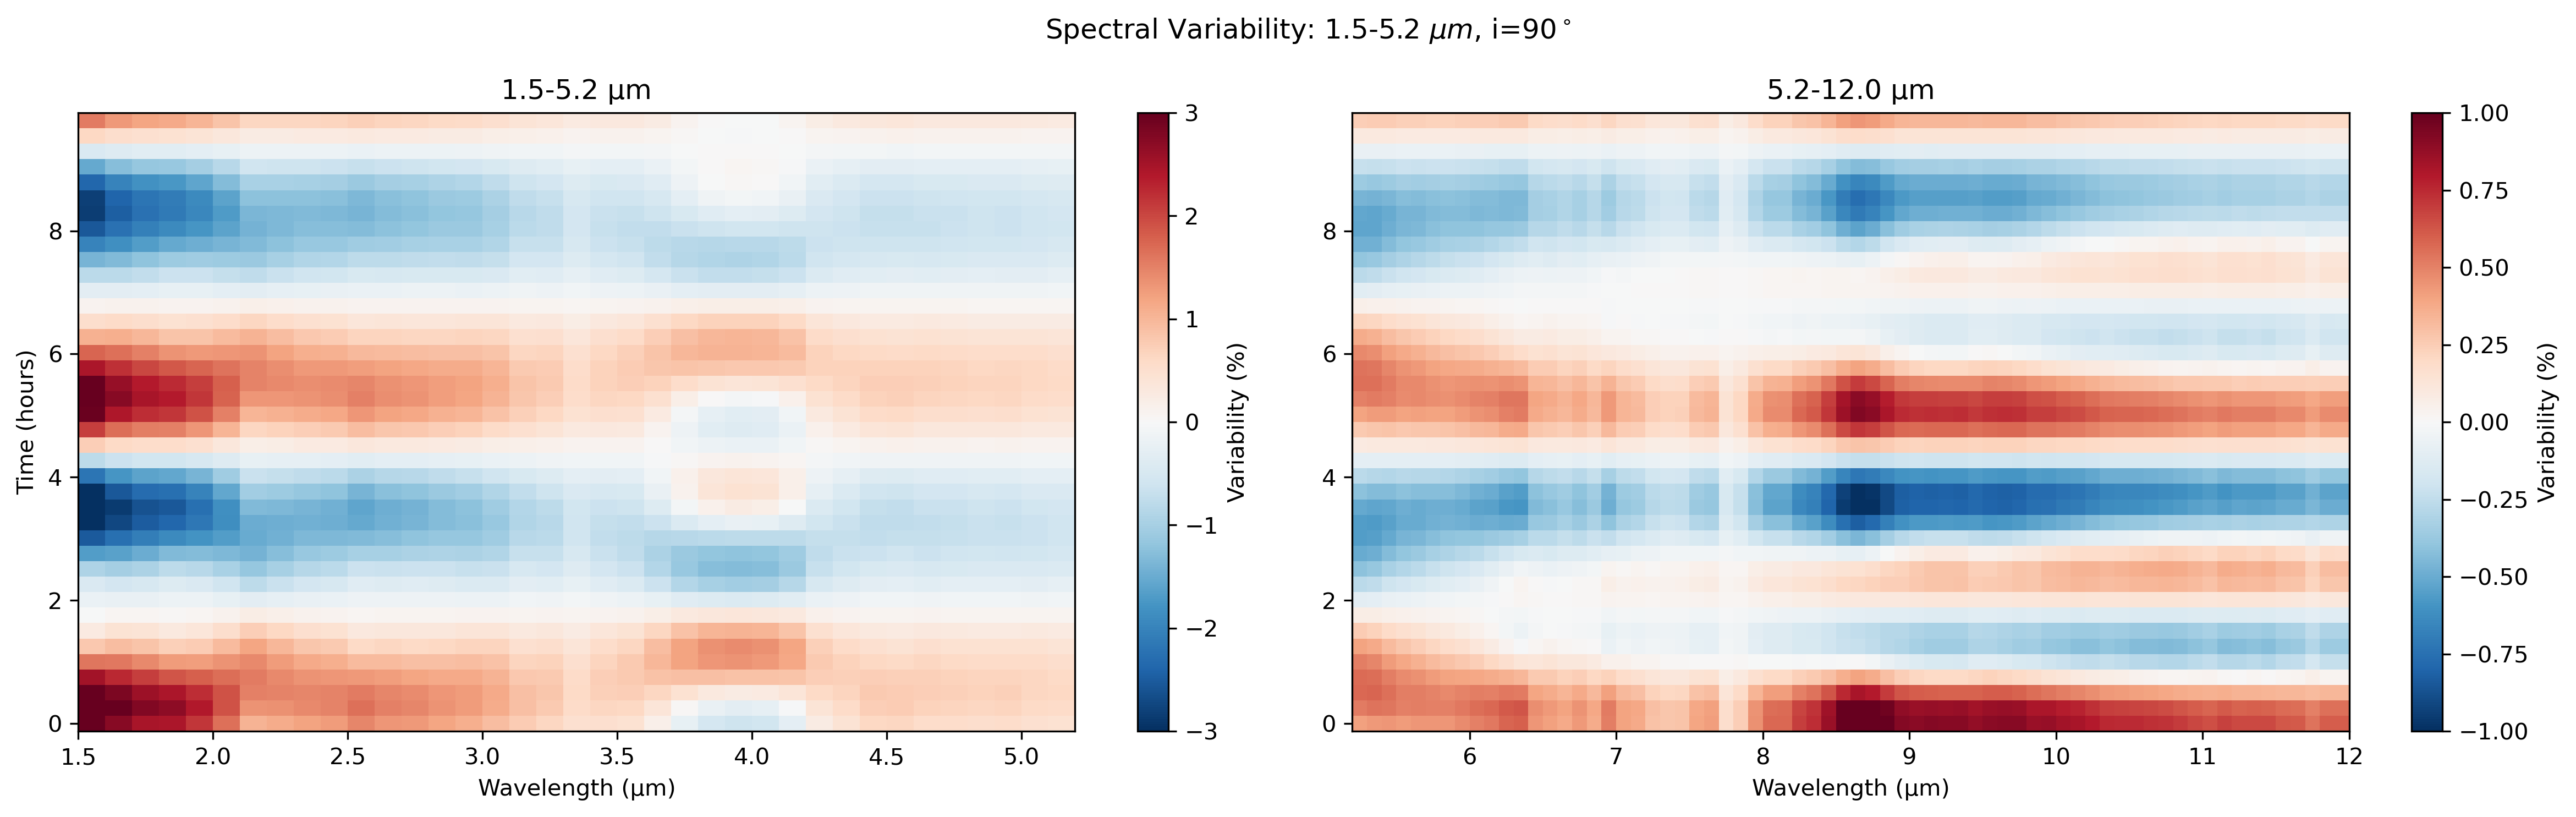

In [27]:
inclin = '90'
save = False
# save = True

saveName = os.path.join(plotDir,f'k1k2_spectral_variability_map_[5-10um].pdf') if save else None

# composite_spectra_ts, time_array, wave_bin=0.1, t_min=0.0, t_max=10.0,
                                # split_wave=6.0, wave_range_full=(1.0, 12.0),
                                # inclin=None, cmap='RdBu_r', save_path=None, figshape=(14, 5),
                                # vmin1=None, vmax1=None, vmin2=None, vmax2=None, title='none'

fig, axs, variability = plot_variability_map_split(
    specs_k1k2_ts[inclin], time_k1k2_ts,
    t_min=0.0, t_max=10.0,
    split_wave=5.2, wave_range_full=(1.5, 12.0),
    wave_bin=0.1,
    vmin1=-3, vmax1=+3, vmin2=-1, vmax2=+1,
    inclin=inclin, 
    cmap='RdBu_r', 
    figshape=(16, 5),
    save_path=saveName,
    title = r'Spectral Variability: 1.5-5.2$~\mu m$, i=90$^\circ$ '
    )

### timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e6+1e6)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20

In [119]:
### Reading in configuration k1k2
### Read the photometry file
photometryh5dir = '/Users/nguyendat/Documents/GitHub/polarVortexJwst/rendering/atm_renderer/output/'
specConfigName_k1k2 = 'k1k2_test_1400K_multiKzz(1e6+1e6)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20' 

photrunName_k1k2_ts = 'test_polar_v5_static.h5'
phot_k1k2_ts, specs_k1k2_ts, codecs_k1k2_ts, codec_k1k2_loaded_ts = read_spec_codecs(photrunName_k1k2_ts, specConfigName=specConfigName_k1k2) 
time_k1k2_ts = phot_k1k2_ts['0']['time_array'] # load the time indices 

### Somes helpful metadata
# codec length
n = len(codec_k1k2_loaded_ts.spectra_assignments.keys())

Added codec 'feature_type' with 2 values: [1, 2]
Added codec 'cloud_thickness' with 20 values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Generated 40 codec combinations
ID range: 0-39
Loaded codec mapping from /Users/nguyendat/Documents/GitHub/polarVortexJwst/spec_module/timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e6+1e6)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20/codec_config.json
  Codec combinations: 40
  Spectra assignments: 40


Saved variability map to /Users/nguyendat/Documents/GitHub/polarVortexJwst/paperPlots_updatedSiO2/[variability]_90_k1k2_test_1400K_multiKzz(1e6+1e6)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20.pdf


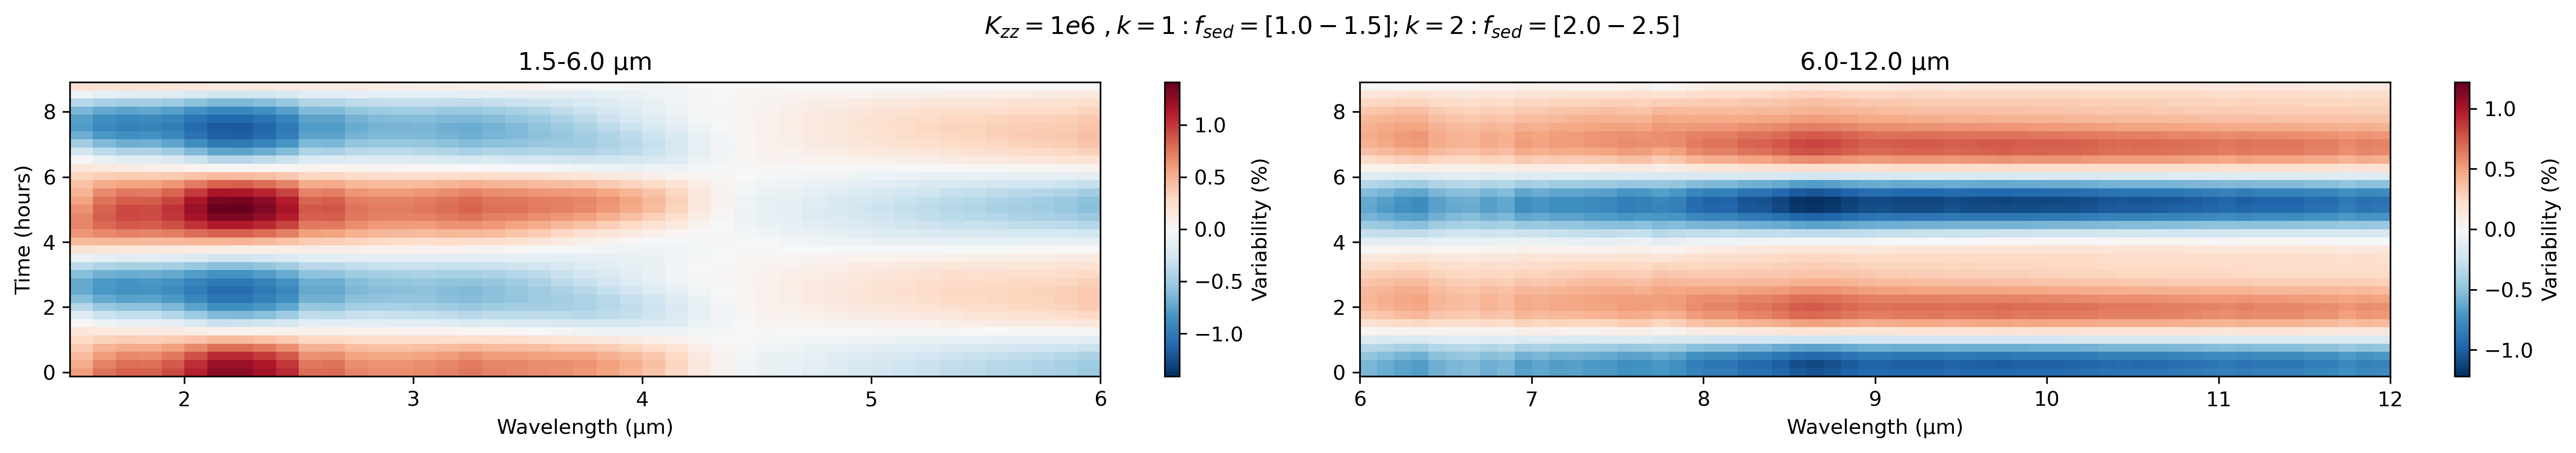

In [ ]:
inclin = '90'
save = False
# save = True

saveName = os.path.join(plotDir,f'[variability]_{inclin}_{specConfigName_k1k2}.pdf') if save else None

# composite_spectra_ts, time_array, wave_bin=0.1, t_min=0.0, t_max=10.0,
                                # split_wave=6.0, wave_range_full=(1.0, 12.0),
                                # inclin=None, cmap='RdBu_r', save_path=None, figshape=(14, 5),
                                # vmin1=None, vmax1=None, vmin2=None, vmax2=None, title='none'

fig, axs, variability = plot_variability_map_split(
    specs_k1k2_ts[inclin], time_k1k2_ts,
    t_min=0.0, t_max=9.0,
    split_wave=6, wave_range_full=(1.5, 12.0),
    wave_bin=0.1,
    # vmin1=-1, vmax1=+1, vmin2=-1, vmax2=+1,
    inclin=inclin, 
    cmap='RdBu_r', 
    figshape=(18, 3),
    save_path=saveName,
    # title = f'{specConfigName_k1k2}',
    title = r'$K_{zz}=1e6\ , k=1 : f_{sed}=[1.0-1.5]; k=2 : f_{sed}=[2.0-2.5]$',
    )

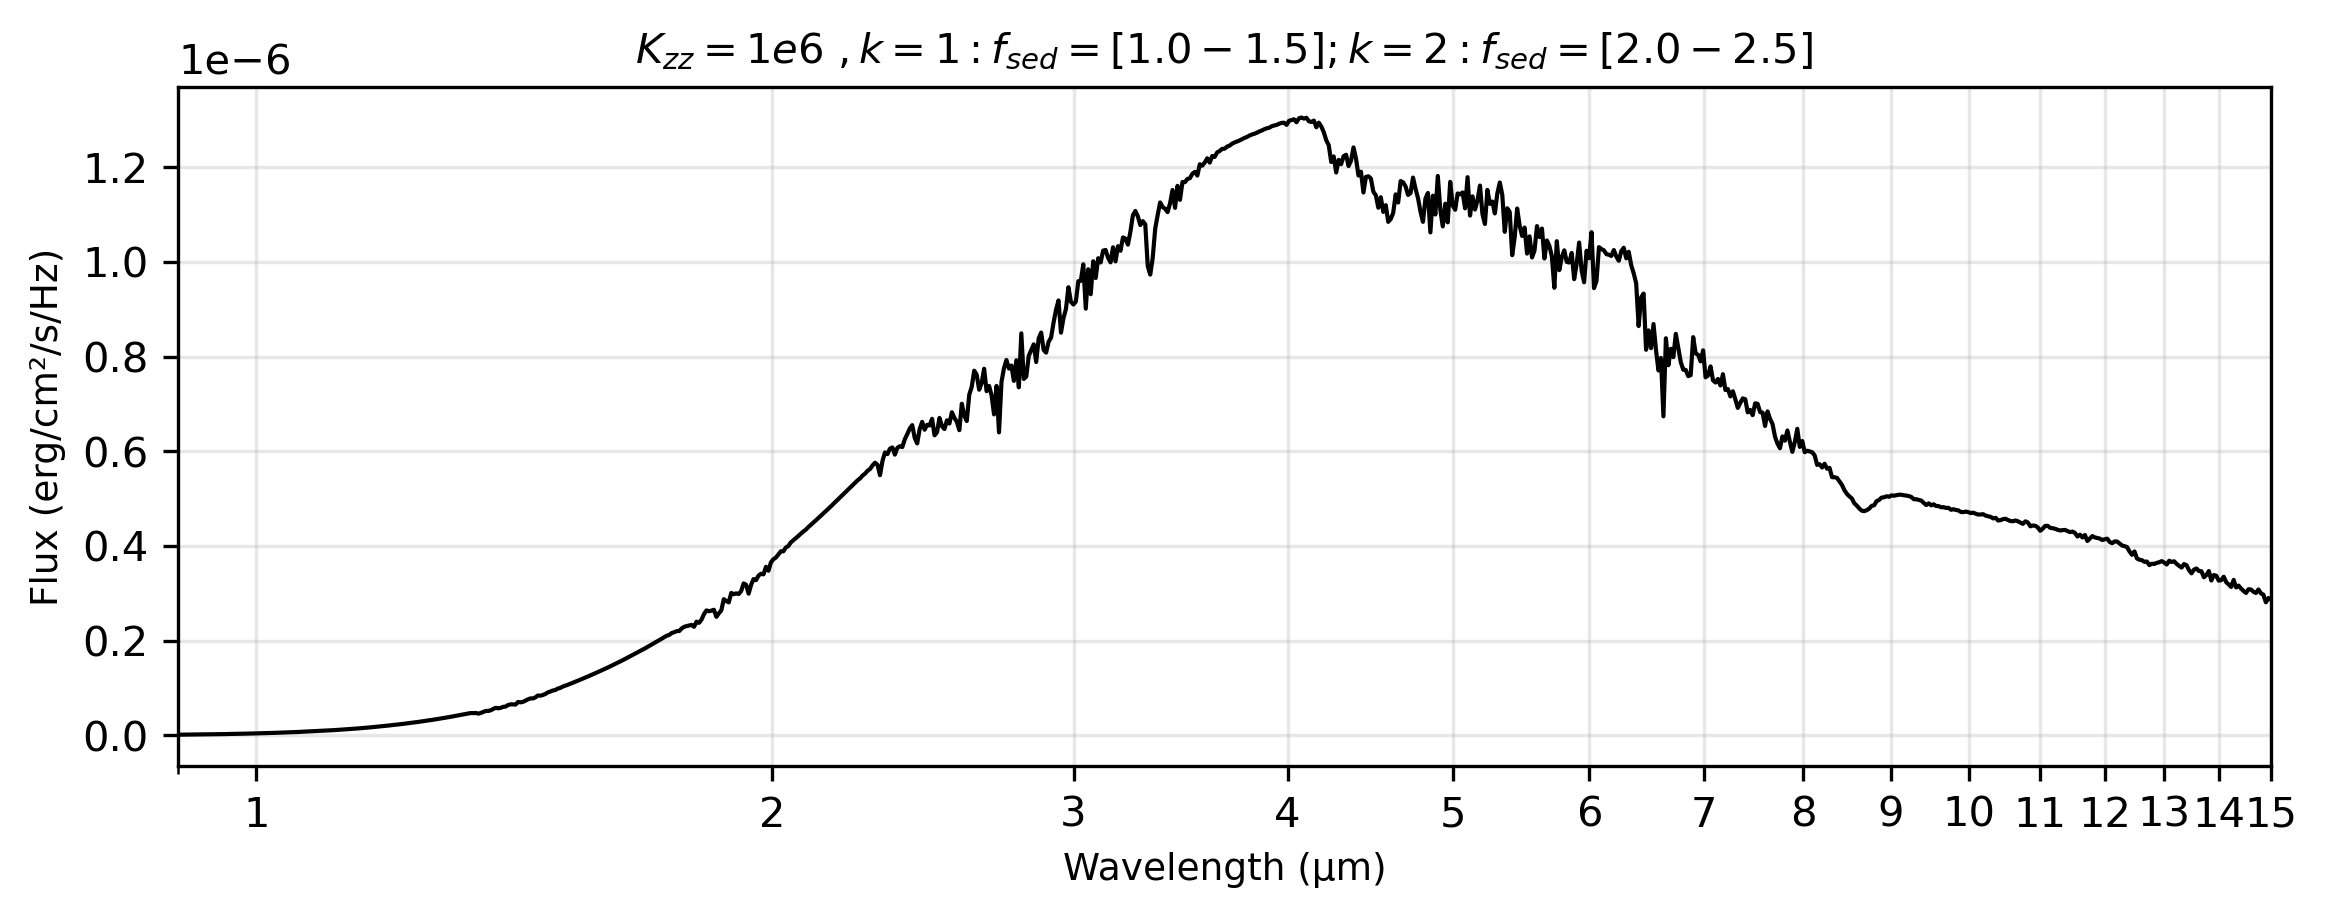

In [ ]:
inclin = '90'
# save = False
save = True

saveName = os.path.join(plotDir,f'[allSpectra]_{inclin}_{specConfigName_k1k2}.pdf') if save else None
fluxsum = np.zeros_like(specs_k1k2_ts[inclin][0]['flux'])  # Initialize fluxsum with the same shape as a single flux array
fig, ax = plt.subplots(figsize=(9, 3), dpi=300)
for codec_id in range(n):  # Plot all codec
    wave_i, flux_i = codec_k1k2_loaded_ts.load_spectrum(codec_id)
    fluxsum += flux_i

# plot the median flux spectrum
mean_flux = fluxsum / n
ax.plot(wave_i, mean_flux, alpha=1, lw=1, color='black', label='Mean Spectrum')
ax.set_xlabel('Wavelength (μm)', fontsize=9)
ax.set_ylabel('Flux (erg/cm²/s/Hz)', fontsize=9)
# ax.set_xticklabels(fontsize=8)
ax.set_title(r'$K_{zz}=1e6\ , k=1 : f_{sed}=[1.0-1.5]; k=2 : f_{sed}=[2.0-2.5]$', fontsize=10)
ax.set_yscale('linear')
ax.set_xscale('log')
ax.set_xlim(0.9, 15), #ax.set_ylim(0, 2.2e-6)
ax.set_xticks(range(1, 16))
ax.set_xticklabels([str(i) for i in range(1, 16)])
ax.grid(True, alpha=0.3)

if save:
    plt.savefig(saveName, dpi=300, bbox_inches='tight')
    print(f"Saved all spectra plot to {saveName}")

### timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e7)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20

In [121]:
# timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e7)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20
### Reading in configuration k1k2
### Read the photometry file
photometryh5dir = '/Users/nguyendat/Documents/GitHub/polarVortexJwst/rendering/atm_renderer/output/'
specConfigName_k1k2 = 'k1k2_test_1400K_multiKzz(1e7+1e7)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20' 

photrunName_k1k2_ts = 'test_polar_v5_static.h5'
phot_k1k2_ts, specs_k1k2_ts, codecs_k1k2_ts, codec_k1k2_loaded_ts = read_spec_codecs(photrunName_k1k2_ts, specConfigName=specConfigName_k1k2) 
time_k1k2_ts = phot_k1k2_ts['0']['time_array'] # load the time indices 

### Somes helpful metadata
# codec length
n = len(codec_k1k2_loaded_ts.spectra_assignments.keys())

Added codec 'feature_type' with 2 values: [1, 2]
Added codec 'cloud_thickness' with 20 values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Generated 40 codec combinations
ID range: 0-39
Loaded codec mapping from /Users/nguyendat/Documents/GitHub/polarVortexJwst/spec_module/timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e7)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20/codec_config.json
  Codec combinations: 40
  Spectra assignments: 40


Saved variability map to /Users/nguyendat/Documents/GitHub/polarVortexJwst/paperPlots_updatedSiO2/[variability]_90_k1k2_test_1400K_multiKzz(1e7+1e7)_fsed(1.0-1.5+2.0-2.5)_logg4.5_SiO2_withCH4_n=20.pdf


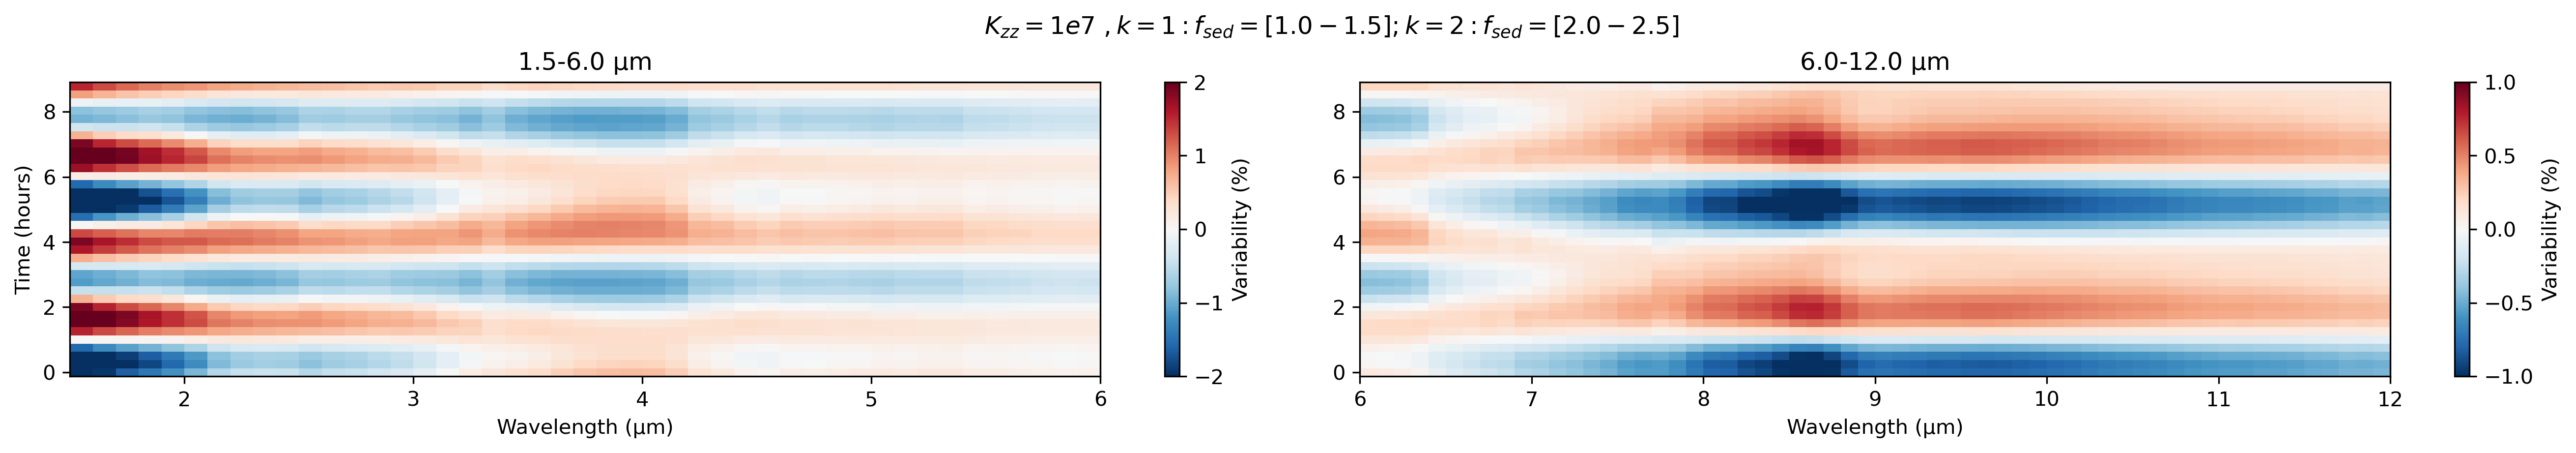

In [ ]:
inclin = '90'
save = False
# save = True

saveName = os.path.join(plotDir,f'[variability]_{inclin}_{specConfigName_k1k2}.pdf') if save else None
# composite_spectra_ts, time_array, wave_bin=0.1, t_min=0.0, t_max=10.0,
                                # split_wave=6.0, wave_range_full=(1.0, 12.0),
                                # inclin=None, cmap='RdBu_r', save_path=None, figshape=(14, 5),
                                # vmin1=None, vmax1=None, vmin2=None, vmax2=None, title='none'

fig, axs, variability = plot_variability_map_split(
    specs_k1k2_ts[inclin], time_k1k2_ts,
    t_min=0.0, t_max=9.0,
    split_wave=6, wave_range_full=(1.5, 12.0),
    wave_bin=0.1,
    vmin1=-2, vmax1=+2, vmin2=-1, vmax2=+1,
    inclin=inclin, 
    cmap='RdBu_r', 
    figshape=(18, 3),
    save_path=saveName,
    # title = f'{specConfigName_k1k2}'
    title = r'$K_{zz}=1e7\ , k=1 : f_{sed}=[1.0-1.5]; k=2 : f_{sed}=[2.0-2.5]$',
    )

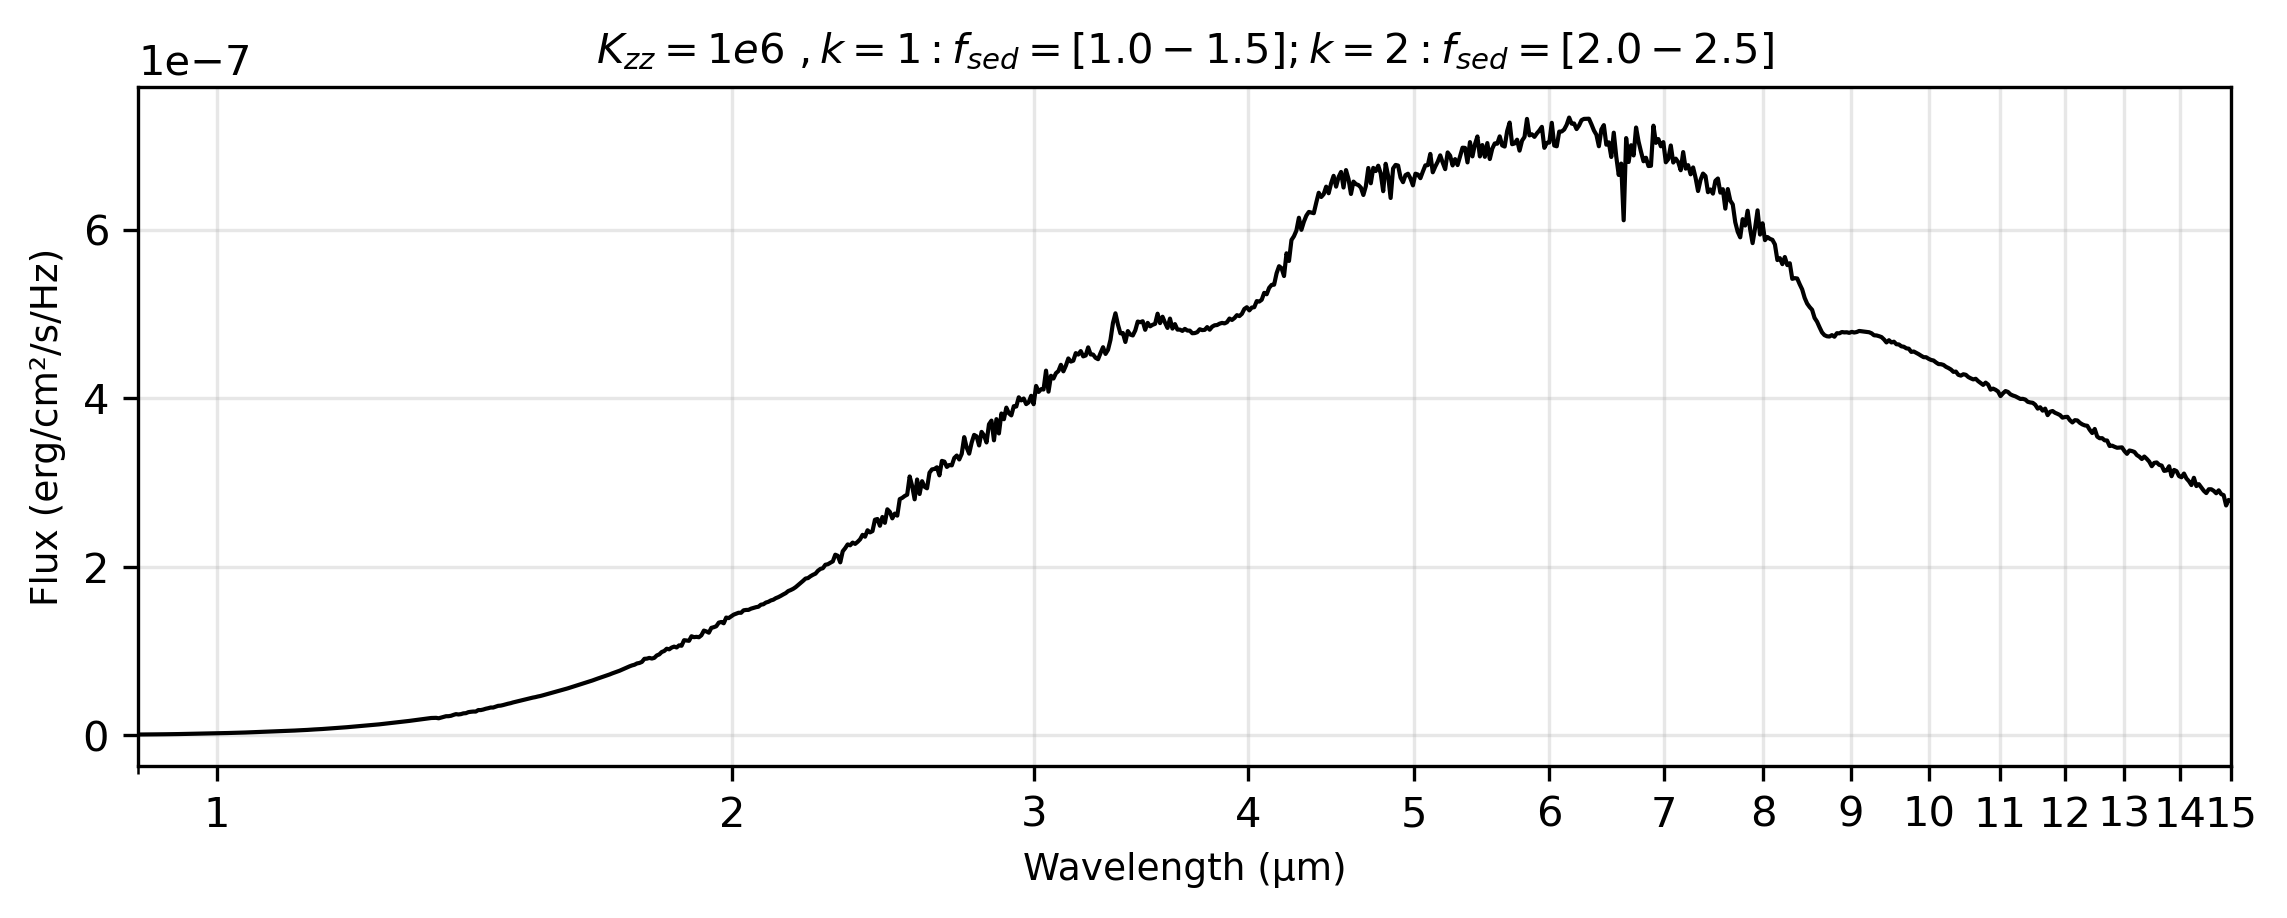

In [ ]:
inclin = '90'
# save = False
save = True

saveName = os.path.join(plotDir,f'[allSpectra]_{inclin}_{specConfigName_k1k2}.pdf') if save else None
fluxsum = np.zeros_like(specs_k1k2_ts[inclin][0]['flux'])  # Initialize fluxsum with the same shape as a single flux array
fig, ax = plt.subplots(figsize=(9, 3), dpi=300)
for codec_id in range(n):  # Plot all codec
    wave_i, flux_i = codec_k1k2_loaded_ts.load_spectrum(codec_id)
    fluxsum += flux_i

# plot the median flux spectrum
mean_flux = fluxsum / n
ax.plot(wave_i, mean_flux, alpha=1, lw=1, color='black', label='Mean Spectrum')
ax.set_xlabel('Wavelength (μm)', fontsize=9)
ax.set_ylabel('Flux (erg/cm²/s/Hz)', fontsize=9)
# ax.set_xticklabels(fontsize=8)
ax.set_title(r'$K_{zz}=1e6\ , k=1 : f_{sed}=[1.0-1.5]; k=2 : f_{sed}=[2.0-2.5]$', fontsize=10)
ax.set_yscale('linear')
ax.set_xscale('log')
ax.set_xlim(0.9, 15), #ax.set_ylim(0, 2.2e-6)
ax.set_xticks(range(1, 16))
ax.set_xticklabels([str(i) for i in range(1, 16)])
ax.grid(True, alpha=0.3)

if save:
    plt.savefig(saveName, dpi=300, bbox_inches='tight')
    print(f"Saved all spectra plot to {saveName}")

### timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e8+1e7)_fsed(1.0-1.50+1.0-1.5)_logg4.5_SiO2_withCH4_n=20

In [123]:
# timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e8+1e7)_fsed(1.0-1.50+1.0-1.5)_logg4.5_SiO2_withCH4_n=20
### Reading in configuration k1k2
### Read the photometry file
photometryh5dir = '/Users/nguyendat/Documents/GitHub/polarVortexJwst/rendering/atm_renderer/output/'
specConfigName_k1k2 = 'k1k2_test_1400K_multiKzz(1e8+1e7)_fsed(1.0-1.50+1.0-1.5)_logg4.5_SiO2_withCH4_n=20' 

photrunName_k1k2_ts = 'test_polar_v5_static.h5'
phot_k1k2_ts, specs_k1k2_ts, codecs_k1k2_ts, codec_k1k2_loaded_ts = read_spec_codecs(photrunName_k1k2_ts, specConfigName=specConfigName_k1k2) 
time_k1k2_ts = phot_k1k2_ts['0']['time_array'] # load the time indices 

### Somes helpful metadata
# codec length
n = len(codec_k1k2_loaded_ts.spectra_assignments.keys())

Added codec 'feature_type' with 2 values: [1, 2]
Added codec 'cloud_thickness' with 20 values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Generated 40 codec combinations
ID range: 0-39
Loaded codec mapping from /Users/nguyendat/Documents/GitHub/polarVortexJwst/spec_module/timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e8+1e7)_fsed(1.0-1.50+1.0-1.5)_logg4.5_SiO2_withCH4_n=20/codec_config.json
  Codec combinations: 40
  Spectra assignments: 40


Saved variability map to /Users/nguyendat/Documents/GitHub/polarVortexJwst/paperPlots_updatedSiO2/[variability]_90_k1k2_test_1400K_multiKzz(1e8+1e7)_fsed(1.0-1.50+1.0-1.5)_logg4.5_SiO2_withCH4_n=20.pdf


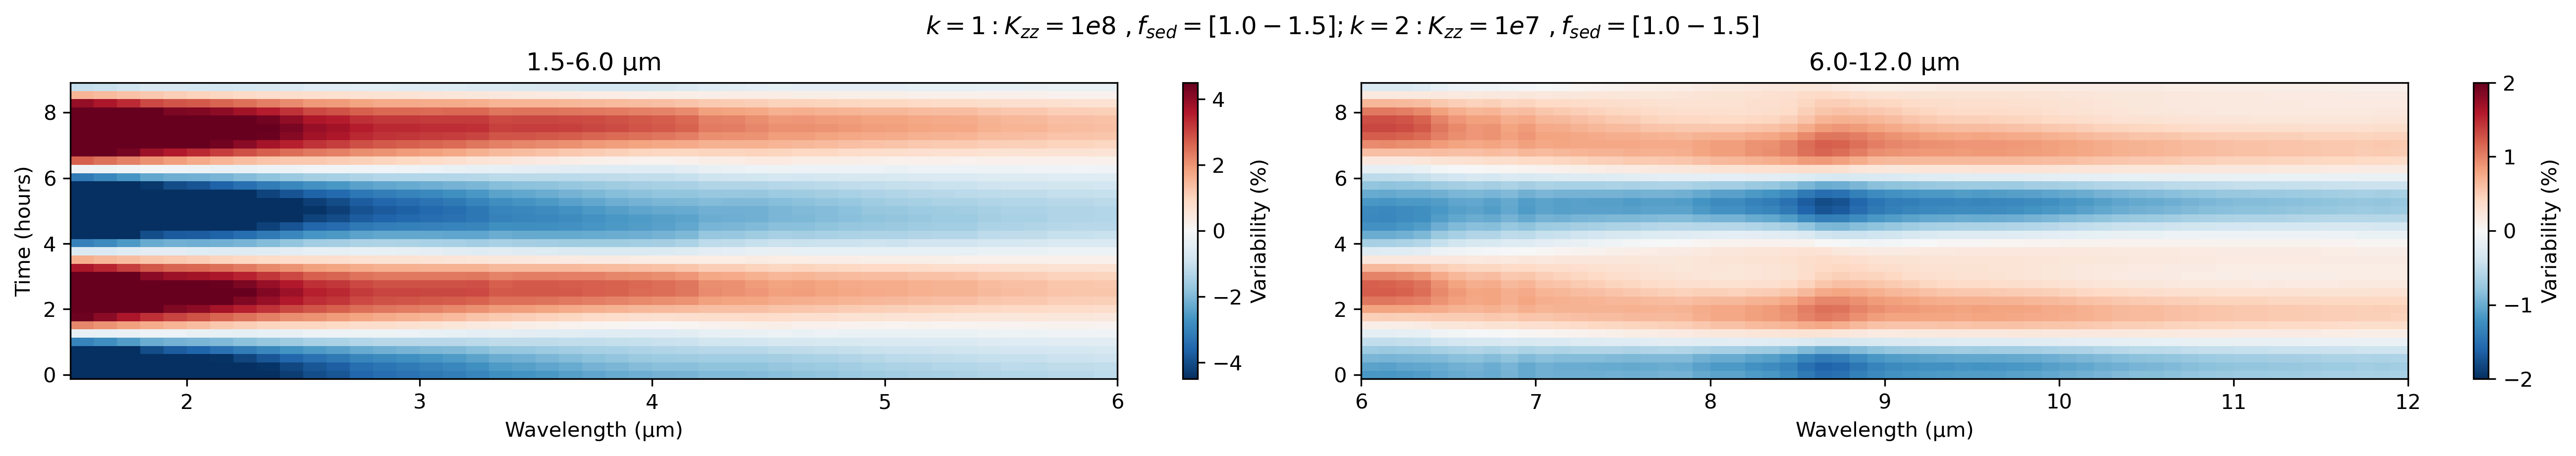

In [62]:
inclin = '90'
# save = False
save = True

saveName = os.path.join(plotDir,f'[variability]_{inclin}_{specConfigName_k1k2}.pdf') if save else None
# composite_spectra_ts, time_array, wave_bin=0.1, t_min=0.0, t_max=10.0,
                                # split_wave=6.0, wave_range_full=(1.0, 12.0),
                                # inclin=None, cmap='RdBu_r', save_path=None, figshape=(14, 5),
                                # vmin1=None, vmax1=None, vmin2=None, vmax2=None, title='none'

fig, axs, variability = plot_variability_map_split(
    specs_k1k2_ts[inclin], time_k1k2_ts,
    t_min=0.0, t_max=9.0,
    split_wave=6, wave_range_full=(1.5, 12.0),
    wave_bin=0.1,
    vmin1=-4.5, vmax1=+4.5, vmin2=-2, vmax2=+2,
    inclin=inclin, 
    cmap='RdBu_r', 
    figshape=(18, 3),
    save_path=saveName,
    # title = f'{specConfigName_k1k2}'
    title = r'$k=1 : K_{zz}=1e8\ ,  f_{sed}=[1.0-1.5]; k=2 : K_{zz}=1e7\ , f_{sed}=[1.0-1.5]$',
    )

### timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(1.0-1.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20

In [63]:
# timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(1.0-1.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20
### Reading in configuration k1k2
### Read the photometry file
photometryh5dir = '/Users/nguyendat/Documents/GitHub/polarVortexJwst/rendering/atm_renderer/output/'
specConfigName_k1k2 = 'k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(1.0-1.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20' 

photrunName_k1k2_ts = 'test_polar_v5_static.h5'
phot_k1k2_ts, specs_k1k2_ts, codecs_k1k2_ts, codec_k1k2_loaded_ts = read_spec_codecs(photrunName_k1k2_ts, specConfigName=specConfigName_k1k2) 
time_k1k2_ts = phot_k1k2_ts['0']['time_array'] # load the time indices 

### Somes helpful metadata
# codec length
n = len(codec_k1k2_loaded_ts.spectra_assignments.keys())

Added codec 'feature_type' with 2 values: [1, 2]
Added codec 'cloud_thickness' with 20 values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Generated 40 codec combinations
ID range: 0-39
Loaded codec mapping from /Users/nguyendat/Documents/GitHub/polarVortexJwst/spec_module/timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(1.0-1.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20/codec_config.json
  Codec combinations: 40
  Spectra assignments: 40


Saved variability map to /Users/nguyendat/Documents/GitHub/polarVortexJwst/paperPlots_updatedSiO2/[variability]_90_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(1.0-1.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20.pdf


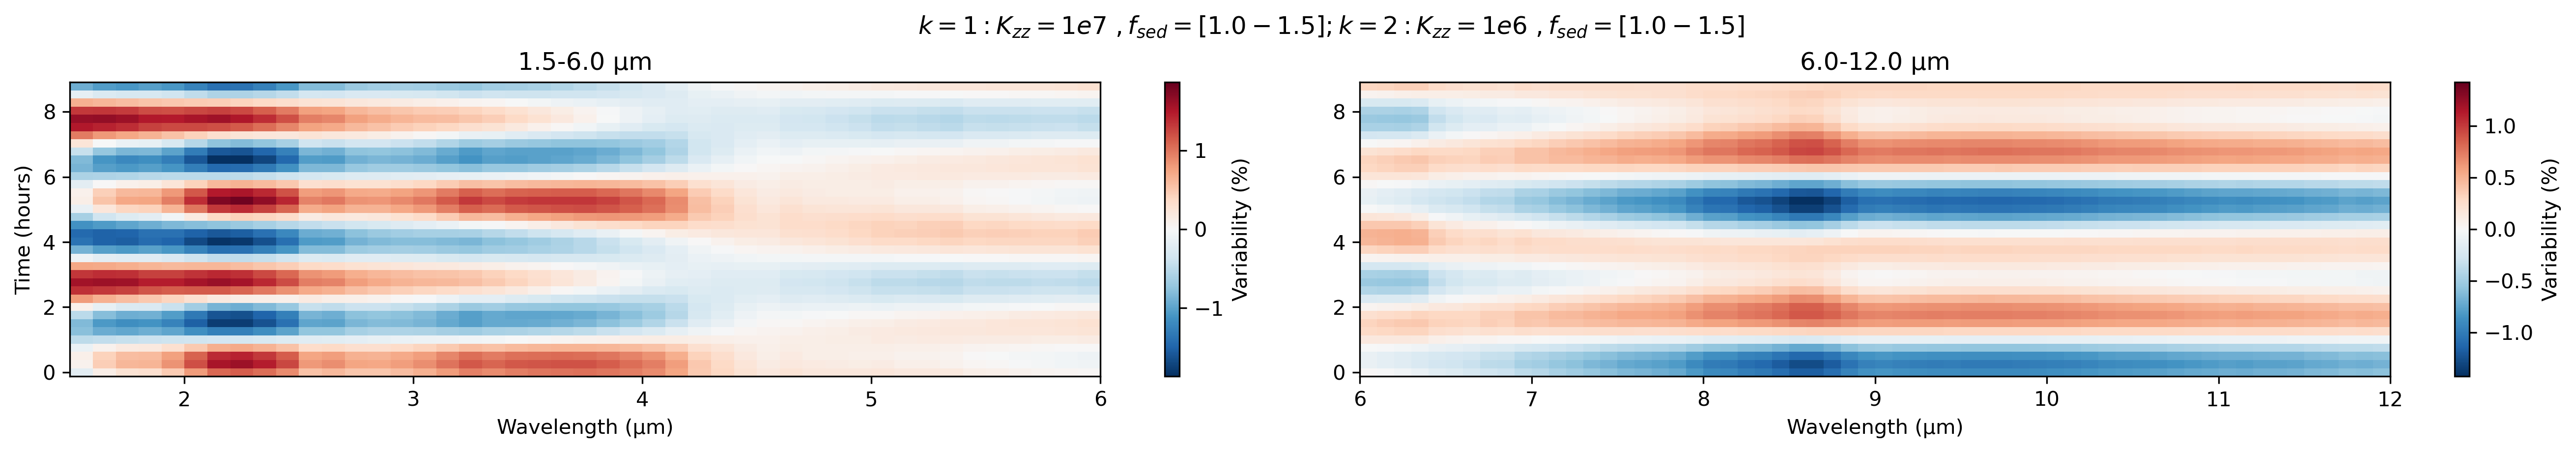

In [64]:
inclin = '90'
# save = False
save = True

saveName = os.path.join(plotDir,f'[variability]_{inclin}_{specConfigName_k1k2}.pdf') if save else None
# composite_spectra_ts, time_array, wave_bin=0.1, t_min=0.0, t_max=10.0,
                                # split_wave=6.0, wave_range_full=(1.0, 12.0),
                                # inclin=None, cmap='RdBu_r', save_path=None, figshape=(14, 5),
                                # vmin1=None, vmax1=None, vmin2=None, vmax2=None, title='none'

fig, axs, variability = plot_variability_map_split(
    specs_k1k2_ts[inclin], time_k1k2_ts,
    t_min=0.0, t_max=9.0,
    split_wave=6, wave_range_full=(1.5, 12.0),
    wave_bin=0.1,
    # vmin1=-4.5, vmax1=+4.5, vmin2=-2, vmax2=+2,
    inclin=inclin, 
    cmap='RdBu_r', 
    figshape=(18, 3),
    save_path=saveName,
    # title = f'{specConfigName_k1k2}'
    title = r'$k=1 : K_{zz}=1e7\ ,  f_{sed}=[1.0-1.5]; k=2 : K_{zz}=1e6\ , f_{sed}=[1.0-1.5]$',
    )

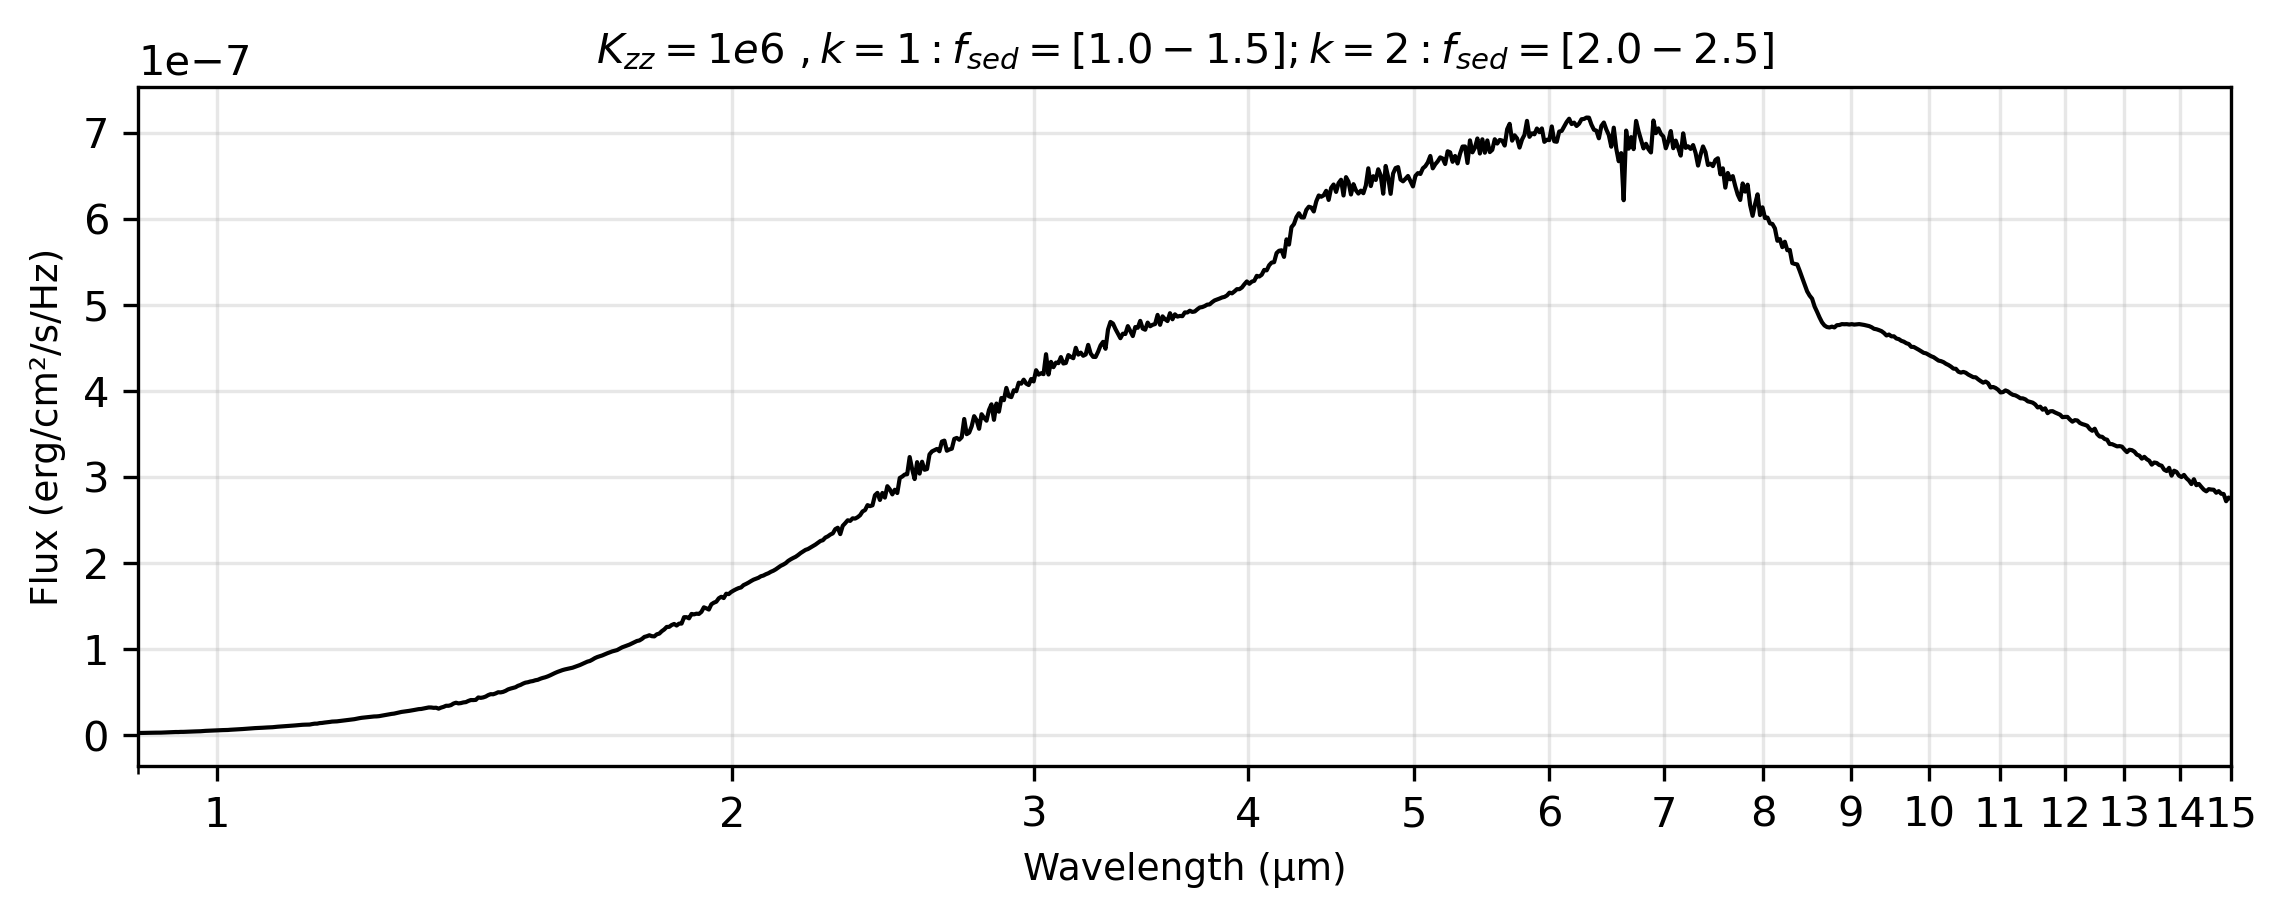

In [ ]:
inclin = '90'
# save = False
save = True

saveName = os.path.join(plotDir,f'[allSpectra]_{inclin}_{specConfigName_k1k2}.pdf') if save else None
fluxsum = np.zeros_like(specs_k1k2_ts[inclin][0]['flux'])  # Initialize fluxsum with the same shape as a single flux array
fig, ax = plt.subplots(figsize=(9, 3), dpi=300)
for codec_id in range(n):  # Plot all codec
    wave_i, flux_i = codec_k1k2_loaded_ts.load_spectrum(codec_id)
    fluxsum += flux_i

# plot the median flux spectrum
mean_flux = fluxsum / n
ax.plot(wave_i, mean_flux, alpha=1, lw=1, color='black', label='Mean Spectrum')
ax.set_xlabel('Wavelength (μm)', fontsize=9)
ax.set_ylabel('Flux (erg/cm²/s/Hz)', fontsize=9)
# ax.set_xticklabels(fontsize=8)
ax.set_title(r'$K_{zz}=1e6\ , k=1 : f_{sed}=[1.0-1.5]; k=2 : f_{sed}=[2.0-2.5]$', fontsize=10)
ax.set_yscale('linear')
ax.set_xscale('log')
ax.set_xlim(0.9, 15), #ax.set_ylim(0, 2.2e-6)
ax.set_xticks(range(1, 16))
ax.set_xticklabels([str(i) for i in range(1, 16)])
ax.grid(True, alpha=0.3)

if save:
    plt.savefig(saveName, dpi=300, bbox_inches='tight')
    print(f"Saved all spectra plot to {saveName}")

### timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(2.0-2.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20

In [126]:
# timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(2.0-2.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20
### Reading in configuration k1k2
### Read the photometry file
photometryh5dir = '/Users/nguyendat/Documents/GitHub/polarVortexJwst/rendering/atm_renderer/output/'
specConfigName_k1k2 = 'k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(2.0-2.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20' 

photrunName_k1k2_ts = 'test_polar_v5_static.h5'
phot_k1k2_ts, specs_k1k2_ts, codecs_k1k2_ts, codec_k1k2_loaded_ts = read_spec_codecs(photrunName_k1k2_ts, specConfigName=specConfigName_k1k2) 
time_k1k2_ts = phot_k1k2_ts['0']['time_array'] # load the time indices 

### Somes helpful metadata
# codec length
n = len(codec_k1k2_loaded_ts.spectra_assignments.keys())

Added codec 'feature_type' with 2 values: [1, 2]
Added codec 'cloud_thickness' with 20 values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Generated 40 codec combinations
ID range: 0-39
Loaded codec mapping from /Users/nguyendat/Documents/GitHub/polarVortexJwst/spec_module/timeseries_test_polar_v5_static_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(2.0-2.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20/codec_config.json
  Codec combinations: 40
  Spectra assignments: 40


Saved variability map to /Users/nguyendat/Documents/GitHub/polarVortexJwst/paperPlots_updatedSiO2/[variability]_90_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(2.0-2.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20.pdf


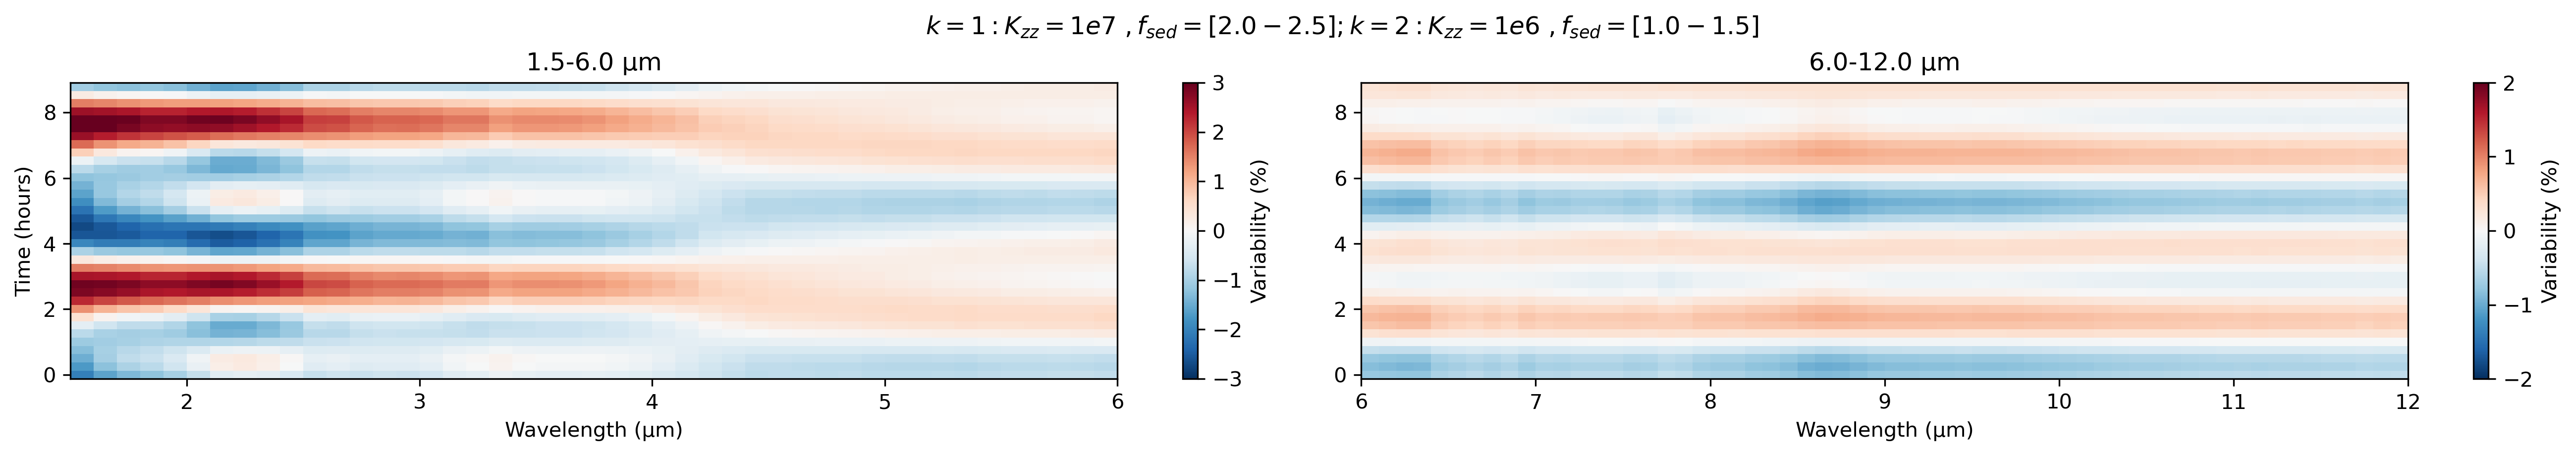

In [72]:
inclin = '90'
# save = False
save = True

saveName = os.path.join(plotDir,f'[variability]_{inclin}_{specConfigName_k1k2}.pdf') if save else None
# composite_spectra_ts, time_array, wave_bin=0.1, t_min=0.0, t_max=10.0,
                                # split_wave=6.0, wave_range_full=(1.0, 12.0),
                                # inclin=None, cmap='RdBu_r', save_path=None, figshape=(14, 5),
                                # vmin1=None, vmax1=None, vmin2=None, vmax2=None, title='none'

fig, axs, variability = plot_variability_map_split(
    specs_k1k2_ts[inclin], time_k1k2_ts,
    t_min=0.0, t_max=9.0,
    split_wave=6, wave_range_full=(1.5, 12.0),
    wave_bin=0.1,
    vmin1=-3, vmax1=+3, vmin2=-2, vmax2=+2,
    inclin=inclin, 
    cmap='RdBu_r', 
    figshape=(18, 3),
    save_path=saveName,
    # title = f'{specConfigName_k1k2}'
    title = r'$k=1 : K_{zz}=1e7\ ,  f_{sed}=[2.0-2.5]; k=2 : K_{zz}=1e6\ , f_{sed}=[1.0-1.5]$',
    )

Saved all spectra plot to /Users/nguyendat/Documents/GitHub/polarVortexJwst/paperPlots_updatedSiO2/[allSpectra]_90_k1k2_test_1400K_multiKzz(1e7+1e6)_fsed(2.0-2.5+1.0-1.5)_logg4.5_SiO2_withCH4_n=20.pdf


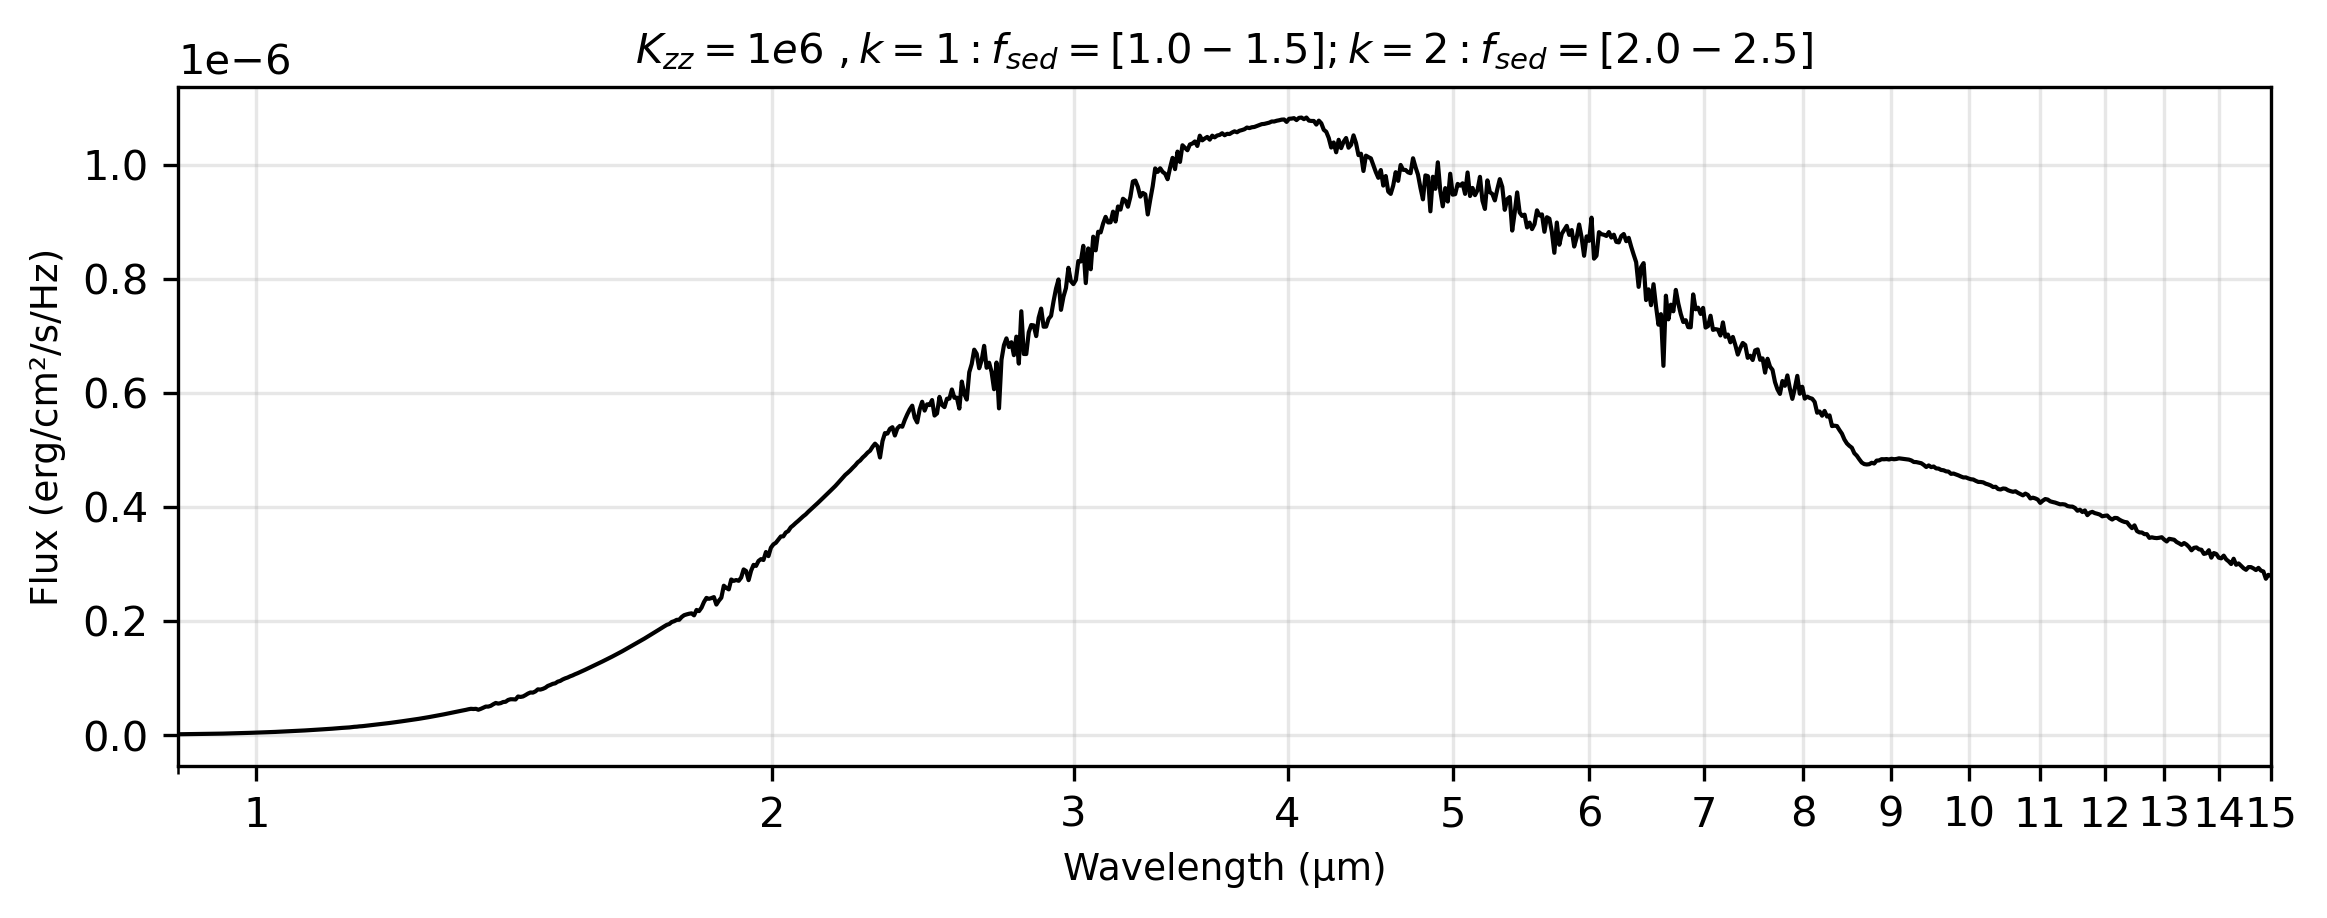

In [128]:
inclin = '90'
# save = False
save = True

saveName = os.path.join(plotDir,f'[allSpectra]_{inclin}_{specConfigName_k1k2}.pdf') if save else None
fluxsum = np.zeros_like(specs_k1k2_ts[inclin][0]['flux'])  # Initialize fluxsum with the same shape as a single flux array
fig, ax = plt.subplots(figsize=(9, 3), dpi=300)
for codec_id in range(n):  # Plot all codec
    wave_i, flux_i = codec_k1k2_loaded_ts.load_spectrum(codec_id)
    fluxsum += flux_i

# plot the median flux spectrum
mean_flux = fluxsum / n
ax.plot(wave_i, mean_flux, alpha=1, lw=1, color='black', label='Mean Spectrum')
ax.set_xlabel('Wavelength (μm)', fontsize=9)
ax.set_ylabel('Flux (erg/cm²/s/Hz)', fontsize=9)
# ax.set_xticklabels(fontsize=8)
ax.set_title(r'$K_{zz}=1e6\ , k=1 : f_{sed}=[1.0-1.5]; k=2 : f_{sed}=[2.0-2.5]$', fontsize=10)
ax.set_yscale('linear')
ax.set_xscale('log')
ax.set_xlim(0.9, 15), #ax.set_ylim(0, 2.2e-6)
ax.set_xticks(range(1, 16))
ax.set_xticklabels([str(i) for i in range(1, 16)])
ax.grid(True, alpha=0.3)

if save:
    plt.savefig(saveName, dpi=300, bbox_inches='tight')
    print(f"Saved all spectra plot to {saveName}")